# E-commerce Sales Analysis

## Introduction

This project analyzes e-commerce sales data using Python, NumPy, Pandas, and Matplotlib. The main objective is to understand sales performance, identify revenue trends, and discover useful business insights from the available dataset.

The analysis focuses on monthly revenue, product category performance, city-wise sales, customer behavior, and payment methods.

### Project Objectives
- Analyze overall sales and revenue performance.
- Identify the highest- and lowest-performing months.
- Compare revenue across product categories and cities.
- Examine order counts and revenue per order.
- Visualize important findings and provide data-driven recommendations.

In [1]:
import pandas as pd
import numpy as np

## Dataset Overview

The dataset contains e-commerce transaction records, including customer details, product information, order dates, payment methods, ratings, and sales quantities.

### Key Columns
- **Order ID:** Unique identifier for an order.
- **Customer ID:** Identifier for a customer.
- **Gender and Age:** Customer demographic information.
- **Product Category and Product Name:** Information about purchased products.
- **Quantity and Price:** Number of units purchased and product price.
- **Order Date:** Date of the transaction.
- **Payment Method:** Method used to complete the payment.
- **City:** Customer's city.
- **Rating:** Customer rating for the purchase.

The dataset is loaded from a CSV file and explored using Pandas to understand its structure and contents.

In [2]:
df = pd.read_csv("ecommerce_sales_data.csv")
df.head()

,Order ID,Customer ID,Gender,Age,Product Category,Product Name,Quantity,Price,Order Date,Payment Method,City,Rating
0,ORD0001,CUST9376,Female,43,Home,Lamp,1,1368.69,07-06-2025,Cash on Delivery,Hyderabad,3
1,ORD0002,CUST3289,Male,57,Toys,Lego Set,5,782.44,11-12-2024,Cash on Delivery,Chennai,5
2,ORD0003,CUST6409,Female,53,Clothing,Jacket,1,3676.18,05-05-2025,Credit Card,Bangalore,4
3,ORD0004,CUST8815,Female,51,Beauty,Perfume,2,4836.37,25-06-2025,Cash on Delivery,Mumbai,5
4,ORD0005,CUST1018,Female,39,Electronics,Smartphone,4,3580.24,25-12-2024,UPI,Kolkata,3


## Data Cleaning and Preparation

Data cleaning helps ensure that the dataset is suitable for analysis. The dataset was checked for missing values, duplicate records, and appropriate data types.

### Preparation Steps
- Inspected the dataset structure and column names.
- Checked for missing values and duplicate records.
- Calculated revenue using quantity and price.
- Converted the order date column into a datetime format.
- Extracted month and year information for time-based analysis.

These preparation steps help improve data consistency and support accurate analysis.

**Note:** Data quality checks and transformations were performed using Pandas.

In [3]:
df.shape

(100, 12)

In [4]:
df.columns

Index(['Order ID', 'Customer ID', 'Gender', 'Age', 'Product Category',
       'Product Name', 'Quantity', 'Price', 'Order Date', 'Payment Method',
       'City', 'Rating'],
      dtype='str')

In [5]:
df.dtypes

Order ID                str
Customer ID             str
Gender                  str
Age                   int64
Product Category        str
Product Name            str
Quantity              int64
Price               float64
Order Date              str
Payment Method          str
City                    str
Rating                int64
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order ID          100 non-null    str    
 1   Customer ID       100 non-null    str    
 2   Gender            100 non-null    str    
 3   Age               100 non-null    int64  
 4   Product Category  100 non-null    str    
 5   Product Name      100 non-null    str    
 6   Quantity          100 non-null    int64  
 7   Price             100 non-null    float64
 8   Order Date        100 non-null    str    
 9   Payment Method    100 non-null    str    
 10  City              100 non-null    str    
 11  Rating            100 non-null    int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 9.5 KB


In [7]:
df.isnull().sum()

Order ID            0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Product Name        0
Quantity            0
Price               0
Order Date          0
Payment Method      0
City                0
Rating              0
dtype: int64

In [8]:
df.duplicated()

0     False
1     False
2     False
3     False
4     False
      ...  
95    False
96    False
97    False
98    False
99    False
Length: 100, dtype: bool

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.describe()

,Age,Quantity,Price,Rating
count,100.000000,100.00000,100.000000,100.000000
mean,37.720000,2.94000,2428.300600,3.000000
std,12.426007,1.44124,1508.115395,1.392621
min,18.000000,1.00000,118.330000,1.000000
25%,28.000000,2.00000,1130.615000,2.000000
50%,37.500000,3.00000,2160.355000,3.000000
75%,49.000000,4.00000,3743.872500,4.000000
max,60.000000,5.00000,4836.370000,5.000000


In [11]:
df["Gender"].unique()

<StringArray>
['Female', 'Male']
Length: 2, dtype: str

In [12]:
df["Product Category"].unique()

<StringArray>
['Home', 'Toys', 'Clothing', 'Beauty', 'Electronics', 'Books']
Length: 6, dtype: str

In [13]:
df["Payment Method"].unique()

<StringArray>
['Cash on Delivery', 'Credit Card', 'UPI', 'Netbanking']
Length: 4, dtype: str

In [14]:
df["City"].unique()

<StringArray>
['Hyderabad', 'Chennai', 'Bangalore', 'Mumbai', 'Kolkata', 'Delhi']
Length: 6, dtype: str

In [15]:
df["Gender"].value_counts()

Gender
Female    51
Male      49
Name: count, dtype: int64

In [16]:
df["Product Category"].value_counts()

Product Category
Clothing       21
Electronics    19
Books          18
Home           17
Beauty         13
Toys           12
Name: count, dtype: int64

In [17]:
df["Payment Method"].value_counts()

Payment Method
Netbanking          29
Cash on Delivery    24
UPI                 24
Credit Card         23
Name: count, dtype: int64

In [18]:
df["City"].value_counts()

City
Chennai      22
Mumbai       20
Kolkata      20
Hyderabad    15
Bangalore    14
Delhi         9
Name: count, dtype: int64

In [19]:
df.groupby("Product Category")["Quantity"].sum()

Product Category
Beauty         35
Books          58
Clothing       56
Electronics    58
Home           51
Toys           36
Name: Quantity, dtype: int64

In [20]:
df.groupby("Product Category")["Price"].mean() 

Product Category
Beauty         2618.192308
Books          2396.831667
Clothing       2261.636667
Electronics    2299.012632
Home           2789.844706
Toys           2253.968333
Name: Price, dtype: float64

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis was performed to understand patterns and relationships within the sales dataset.

### Analysis Performed
- **Monthly Analysis:** Compared monthly revenue, order counts, quantity sold, and revenue per order.
- **Product Category Analysis:** Compared total revenue and quantity sold across product categories.
- **City Analysis:** Examined total revenue, order counts, and revenue per order for each city.
- **Customer Analysis:** Compared sales-related metrics across customer genders and age groups where applicable.
- **Payment Method Analysis:** Examined payment method usage and related sales metrics.
- **Rating Analysis:** Compared customer ratings across relevant groups.

Pandas grouping, aggregation, sorting, and date-handling functions were used to summarize the data and identify useful patterns.

In [21]:
df["Revenue"] = df["Quantity"]*df["Price"]
print(df["Revenue"])

0      1368.69
1      3912.20
2      3676.18
3      9672.74
4     14320.96
        ...   
95     1171.28
96     2502.80
97     4306.44
98    13232.88
99     6813.84
Name: Revenue, Length: 100, dtype: float64


In [22]:
df.groupby("Product Category")["Revenue"].sum()

Product Category
Beauty          84457.92
Books          129177.30
Clothing       121504.99
Electronics    140811.26
Home           136365.47
Toys            81902.93
Name: Revenue, dtype: float64

In [23]:
df.groupby("City")["Revenue"].sum()

City
Bangalore     90184.49
Chennai      109181.81
Delhi         55782.47
Hyderabad    130424.17
Kolkata      190462.98
Mumbai       118183.95
Name: Revenue, dtype: float64

In [24]:
df.groupby("Product Category")["Rating"].mean()

Product Category
Beauty         3.384615
Books          2.888889
Clothing       2.952381
Electronics    2.368421
Home           3.000000
Toys           3.833333
Name: Rating, dtype: float64

In [25]:
df.groupby("City")["Quantity"].sum()

City
Bangalore    39
Chennai      64
Delhi        25
Hyderabad    46
Kolkata      71
Mumbai       49
Name: Quantity, dtype: int64

In [26]:
df.groupby("City")["Price"].mean()

City
Bangalore    2321.602143
Chennai      2118.598636
Delhi        2064.194444
Hyderabad    2713.077333
Kolkata      2731.495500
Mumbai       2490.732000
Name: Price, dtype: float64

In [27]:
df.groupby("Product Category")["Order ID"].count().sort_values(ascending=False)

Product Category
Clothing       21
Electronics    19
Books          18
Home           17
Beauty         13
Toys           12
Name: Order ID, dtype: int64

In [28]:
df.groupby("Payment Method")["Revenue"].sum().sort_values(ascending=False)

Payment Method
Credit Card         205724.70
Netbanking          190707.30
Cash on Delivery    178313.61
UPI                 119474.26
Name: Revenue, dtype: float64

In [29]:
df.groupby("City")["Revenue"].sum().sort_values(ascending=False)

City
Kolkata      190462.98
Hyderabad    130424.17
Mumbai       118183.95
Chennai      109181.81
Bangalore     90184.49
Delhi         55782.47
Name: Revenue, dtype: float64

In [30]:
df.groupby("Payment Method")["Rating"].mean().sort_values(ascending=False)

Payment Method
UPI                 3.458333
Cash on Delivery    3.083333
Netbanking          2.931034
Credit Card         2.521739
Name: Rating, dtype: float64

In [31]:
df.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False)

Product Category
Books          58
Electronics    58
Clothing       56
Home           51
Toys           36
Beauty         35
Name: Quantity, dtype: int64

In [32]:
df.groupby("City")["Price"].mean().sort_values(ascending=False)

City
Kolkata      2731.495500
Hyderabad    2713.077333
Mumbai       2490.732000
Bangalore    2321.602143
Chennai      2118.598636
Delhi        2064.194444
Name: Price, dtype: float64

In [33]:
df.groupby("Payment Method")["Order ID"].count().sort_values(ascending=False)

Payment Method
Netbanking          29
Cash on Delivery    24
UPI                 24
Credit Card         23
Name: Order ID, dtype: int64

In [34]:
df.groupby("Gender")["Age"].mean().sort_values(ascending=False)

Gender
Male      38.714286
Female    36.764706
Name: Age, dtype: float64

In [35]:
df.groupby("Gender")["Revenue"].sum().sort_values(ascending=False)

Gender
Female    350229.35
Male      343990.52
Name: Revenue, dtype: float64

In [36]:
df.groupby("Gender")["Quantity"].sum().sort_values(ascending=False)

Gender
Male      159
Female    135
Name: Quantity, dtype: int64

In [37]:
df.groupby("Product Category")["Revenue"].mean().sort_values(ascending=False)

Product Category
Home           8021.498235
Electronics    7411.118947
Books          7176.516667
Toys           6825.244167
Beauty         6496.763077
Clothing       5785.951905
Name: Revenue, dtype: float64

In [38]:
df.groupby("Product Category")["Rating"].mean().sort_values(ascending=False)

Product Category
Toys           3.833333
Beauty         3.384615
Home           3.000000
Clothing       2.952381
Books          2.888889
Electronics    2.368421
Name: Rating, dtype: float64

In [39]:
df.groupby("Product Category")["Order ID"].count().sort_values(ascending = False)

Product Category
Clothing       21
Electronics    19
Books          18
Home           17
Beauty         13
Toys           12
Name: Order ID, dtype: int64

In [40]:
df.groupby("Payment Method").agg({"Revenue":"sum","Rating":"mean"})

,Revenue,Rating
Payment Method,,
Cash on Delivery,178313.61,3.083333
Credit Card,205724.70,2.521739
Netbanking,190707.30,2.931034
UPI,119474.26,3.458333


In [41]:
df.groupby("Product Category").agg({"Quantity":"sum","Revenue":"sum"}).sort_values(by ="Revenue",ascending=False)

,Quantity,Revenue
Product Category,,
Electronics,58,140811.26
Home,51,136365.47
Books,58,129177.30
Clothing,56,121504.99
Beauty,35,84457.92
Toys,36,81902.93


In [42]:
df.groupby("Product Category").agg({"Quantity":"sum","Revenue":"sum","Rating":"mean"}).sort_values(by="Revenue",ascending=False)

,Quantity,Revenue,Rating
Product Category,,,
Electronics,58,140811.26,2.368421
Home,51,136365.47,3.000000
Books,58,129177.30,2.888889
Clothing,56,121504.99,2.952381
Beauty,35,84457.92,3.384615
Toys,36,81902.93,3.833333


In [43]:
df.groupby("City")["Revenue"].sum().sort_values(ascending=False)

City
Kolkata      190462.98
Hyderabad    130424.17
Mumbai       118183.95
Chennai      109181.81
Bangalore     90184.49
Delhi         55782.47
Name: Revenue, dtype: float64

In [44]:
df.groupby("Product Category")["Revenue"].sum().sort_values(ascending=False)

Product Category
Electronics    140811.26
Home           136365.47
Books          129177.30
Clothing       121504.99
Beauty          84457.92
Toys            81902.93
Name: Revenue, dtype: float64

In [45]:
df.groupby("Payment Method")["Revenue"].sum().sort_values(ascending=False)

Payment Method
Credit Card         205724.70
Netbanking          190707.30
Cash on Delivery    178313.61
UPI                 119474.26
Name: Revenue, dtype: float64

In [46]:
df.groupby("Gender")["Revenue"].sum().sort_values(ascending=False)

Gender
Female    350229.35
Male      343990.52
Name: Revenue, dtype: float64

In [47]:
df.groupby("Product Category")["Rating"].mean().sort_values(ascending=False)

Product Category
Toys           3.833333
Beauty         3.384615
Home           3.000000
Clothing       2.952381
Books          2.888889
Electronics    2.368421
Name: Rating, dtype: float64

In [48]:
df.groupby("City")["Rating"].mean().sort_values(ascending=False)

City
Delhi        3.444444
Bangalore    3.285714
Kolkata      3.100000
Mumbai       2.950000
Chennai      2.863636
Hyderabad    2.600000
Name: Rating, dtype: float64

In [49]:
df.groupby("City")["Quantity"].sum().sort_values(ascending=False)

City
Kolkata      71
Chennai      64
Mumbai       49
Hyderabad    46
Bangalore    39
Delhi        25
Name: Quantity, dtype: int64

In [50]:
df.groupby("Payment Method")["Rating"].mean().sort_values(ascending=False)

Payment Method
UPI                 3.458333
Cash on Delivery    3.083333
Netbanking          2.931034
Credit Card         2.521739
Name: Rating, dtype: float64

In [51]:
df.groupby("City")["Price"].mean().sort_values(ascending=False)

City
Kolkata      2731.495500
Hyderabad    2713.077333
Mumbai       2490.732000
Bangalore    2321.602143
Chennai      2118.598636
Delhi        2064.194444
Name: Price, dtype: float64

In [52]:
df.groupby("Product Category")["Quantity"].sum().sort_values(ascending=False)

Product Category
Books          58
Electronics    58
Clothing       56
Home           51
Toys           36
Beauty         35
Name: Quantity, dtype: int64

In [53]:
df.groupby("Gender")["Quantity"].sum().sort_values(ascending=False)

Gender
Male      159
Female    135
Name: Quantity, dtype: int64

In [54]:
df.groupby("Payment Method")["Order ID"].count().sort_values(ascending=False)

Payment Method
Netbanking          29
Cash on Delivery    24
UPI                 24
Credit Card         23
Name: Order ID, dtype: int64

In [55]:
df.groupby("Product Category")["Revenue"].mean().sort_values(ascending=False)

Product Category
Home           8021.498235
Electronics    7411.118947
Books          7176.516667
Toys           6825.244167
Beauty         6496.763077
Clothing       5785.951905
Name: Revenue, dtype: float64

In [56]:
df.groupby("City")["Order ID"].count().sort_values(ascending = False)

City
Chennai      22
Mumbai       20
Kolkata      20
Hyderabad    15
Bangalore    14
Delhi         9
Name: Order ID, dtype: int64

In [57]:
df.groupby("Gender")["Age"].mean().sort_values(ascending=False)

Gender
Male      38.714286
Female    36.764706
Name: Age, dtype: float64

In [58]:
df.groupby("Product Category")["Price"].mean().sort_values(ascending=False)

Product Category
Home           2789.844706
Beauty         2618.192308
Books          2396.831667
Electronics    2299.012632
Clothing       2261.636667
Toys           2253.968333
Name: Price, dtype: float64

In [59]:
df.groupby("Payment Method")["Order ID"].count().sort_values(ascending=False)

Payment Method
Netbanking          29
Cash on Delivery    24
UPI                 24
Credit Card         23
Name: Order ID, dtype: int64

In [60]:
df.groupby("City").agg({"Revenue":"sum","Order ID":"count"})

,Revenue,Order ID
City,,
Bangalore,90184.49,14
Chennai,109181.81,22
Delhi,55782.47,9
Hyderabad,130424.17,15
Kolkata,190462.98,20
Mumbai,118183.95,20


In [61]:
city_summary =  df.groupby("City").agg({"Revenue":"sum","Order ID":"count"})

In [62]:
city_summary["Revenue Per Order"] = city_summary["Revenue"]/city_summary["Order ID"]

In [63]:
city_summary.sort_values("Revenue Per Order",ascending=False)

,Revenue,Order ID,Revenue Per Order
City,,,
Kolkata,190462.98,20,9523.149000
Hyderabad,130424.17,15,8694.944667
Bangalore,90184.49,14,6441.749286
Delhi,55782.47,9,6198.052222
Mumbai,118183.95,20,5909.197500
Chennai,109181.81,22,4962.809545


In [64]:
df.groupby("Product Category").agg({"Revenue":"sum","Quantity":"sum"})

,Revenue,Quantity
Product Category,,
Beauty,84457.92,35
Books,129177.30,58
Clothing,121504.99,56
Electronics,140811.26,58
Home,136365.47,51
Toys,81902.93,36


In [65]:
prod_cat_summary = df.groupby("Product Category").agg({"Revenue":"sum","Quantity":"sum"})

In [66]:
prod_cat_summary["Revenue Per Quantity"] = prod_cat_summary["Revenue"]/prod_cat_summary["Quantity"]

In [67]:
prod_cat_summary.sort_values("Revenue Per Quantity",ascending = False)

,Revenue,Quantity,Revenue Per Quantity
Product Category,,,
Home,136365.47,51,2673.832745
Electronics,140811.26,58,2427.780345
Beauty,84457.92,35,2413.083429
Toys,81902.93,36,2275.081389
Books,129177.30,58,2227.194828
Clothing,121504.99,56,2169.731964


In [68]:
gender_summary = df.groupby("Gender").agg({"Revenue":"sum","Quantity":"sum","Rating":"mean"})

In [69]:
gender_summary["Revenue Per Quantity"] = gender_summary["Revenue"] / gender_summary["Quantity"]

In [70]:
gender_summary.sort_values("Revenue Per Quantity",ascending = False)

,Revenue,Quantity,Rating,Revenue Per Quantity
Gender,,,,
Female,350229.35,135,3.039216,2594.291481
Male,343990.52,159,2.959184,2163.462390


In [71]:
df.groupby(["Product Category","Gender"]).agg({"Revenue":"sum","Quantity":"sum","Rating":"mean"})

Revenue  Quantity    Rating
Product Category Gender                               
Beauty           Female   22341.39        10  3.500000
                 Male     62116.53        25  3.285714
Books            Female   54234.23        24  3.000000
                 Male     74943.07        34  2.800000
Clothing         Female   46343.45        21  3.300000
                 Male     75161.54        35  2.636364
Electronics      Female  102861.95        40  2.461538
                 Male     37949.31        18  2.166667
Home             Female   71840.26        20  2.571429
                 Male     64525.21        31  3.300000
Toys             Female   52608.07        20  3.857143
                 Male     29294.86        16  3.800000

In [72]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%d-%m-%Y")

In [73]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

In [74]:
df.groupby("Month")["Revenue"].sum().sort_values(ascending=False)

Month
8     94121.76
9     90122.59
6     81203.39
4     77696.72
11    58692.98
1     51865.59
5     48729.15
12    44666.03
7     43345.39
2     39294.12
3     37495.60
10    26986.55
Name: Revenue, dtype: float64

In [75]:
df.groupby("Month")["Order ID"].count().sort_values(ascending=False)

Month
6     12
5     10
7     10
1      9
11     9
8      9
2      8
10     8
4      7
3      7
12     6
9      5
Name: Order ID, dtype: int64

In [76]:
df.groupby("Month")["Revenue"].mean().sort_values(ascending=False)

Month
9     18024.518000
4     11099.531429
8     10457.973333
12     7444.338333
6      6766.949167
11     6521.442222
1      5762.843333
3      5356.514286
2      4911.765000
5      4872.915000
7      4334.539000
10     3373.318750
Name: Revenue, dtype: float64

In [77]:
df.groupby("Month")["Quantity"].sum().sort_values(ascending=False)

Month
6     31
8     30
1     27
2     27
5     26
7     24
9     24
10    22
11    22
4     21
3     20
12    20
Name: Quantity, dtype: int64

In [78]:
df.groupby("Month")["Quantity"].mean().sort_values(ascending=False)

Month
9     4.800000
2     3.375000
8     3.333333
12    3.333333
1     3.000000
4     3.000000
3     2.857143
10    2.750000
5     2.600000
6     2.583333
11    2.444444
7     2.400000
Name: Quantity, dtype: float64

In [79]:
df.groupby("Month").agg({"Revenue":"sum","Quantity":"sum"})

,Revenue,Quantity
Month,,
1,51865.59,27
2,39294.12,27
3,37495.60,20
4,77696.72,21
5,48729.15,26
6,81203.39,31
7,43345.39,24
8,94121.76,30
9,90122.59,24


In [80]:
revenue_summary = df.groupby("Month").agg({"Revenue":"sum","Order ID":"count"})
revenue_summary["Revenue Per Order"] = revenue_summary["Revenue"]/revenue_summary["Order ID"]
revenue_summary.sort_values(ascending=False,by="Revenue Per Order")

,Revenue,Order ID,Revenue Per Order
Month,,,
9,90122.59,5,18024.518000
4,77696.72,7,11099.531429
8,94121.76,9,10457.973333
12,44666.03,6,7444.338333
6,81203.39,12,6766.949167
11,58692.98,9,6521.442222
1,51865.59,9,5762.843333
3,37495.60,7,5356.514286
2,39294.12,8,4911.765000


In [81]:
df.groupby("Month")["Revenue"].agg(["sum","mean"])

,sum,mean
Month,,
1,51865.59,5762.843333
2,39294.12,4911.765000
3,37495.60,5356.514286
4,77696.72,11099.531429
5,48729.15,4872.915000
6,81203.39,6766.949167
7,43345.39,4334.539000
8,94121.76,10457.973333
9,90122.59,18024.518000


In [82]:
df.groupby("Month")["Revenue"].sum().sort_values(ascending=True)

Month
10    26986.55
3     37495.60
2     39294.12
7     43345.39
12    44666.03
5     48729.15
1     51865.59
11    58692.98
4     77696.72
6     81203.39
9     90122.59
8     94121.76
Name: Revenue, dtype: float64

In [83]:
revenue_summary.sort_values(ascending=False,by="Order ID")

,Revenue,Order ID,Revenue Per Order
Month,,,
6,81203.39,12,6766.949167
5,48729.15,10,4872.915000
7,43345.39,10,4334.539000
1,51865.59,9,5762.843333
11,58692.98,9,6521.442222
8,94121.76,9,10457.973333
2,39294.12,8,4911.765000
10,26986.55,8,3373.318750
4,77696.72,7,11099.531429


In [84]:
revenue_summary.sort_values(ascending=False,by="Revenue")

,Revenue,Order ID,Revenue Per Order
Month,,,
8,94121.76,9,10457.973333
9,90122.59,5,18024.518000
6,81203.39,12,6766.949167
4,77696.72,7,11099.531429
11,58692.98,9,6521.442222
1,51865.59,9,5762.843333
5,48729.15,10,4872.915000
12,44666.03,6,7444.338333
7,43345.39,10,4334.539000


In [85]:
df.groupby("Month")["Rating"].mean().sort_values(ascending=False)

Month
2     3.750000
11    3.555556
6     3.500000
12    3.333333
8     3.222222
5     2.900000
3     2.714286
4     2.714286
1     2.666667
7     2.600000
10    2.375000
9     2.200000
Name: Rating, dtype: float64

In [86]:
df.groupby("Month")["Customer ID"].nunique().sort_values(ascending=False)

Month
6     12
5     10
7     10
1      9
11     9
8      9
2      8
10     8
4      7
3      7
12     6
9      5
Name: Customer ID, dtype: int64

## Data Visualization

Matplotlib was used to create charts that make the sales analysis easier to understand.

### Visualizations
- **Monthly Revenue Trend:** Shows how revenue changes throughout the year.
- **Revenue by Product Category:** Compares total revenue across product categories.
- **Revenue by City:** Compares total revenue generated by different cities.

The visualizations help identify high-performing and low-performing periods, categories, and cities.

Each chart includes a suitable title and axis labels to improve readability and interpretation.

In [87]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\User\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [88]:
import matplotlib.pyplot as plt

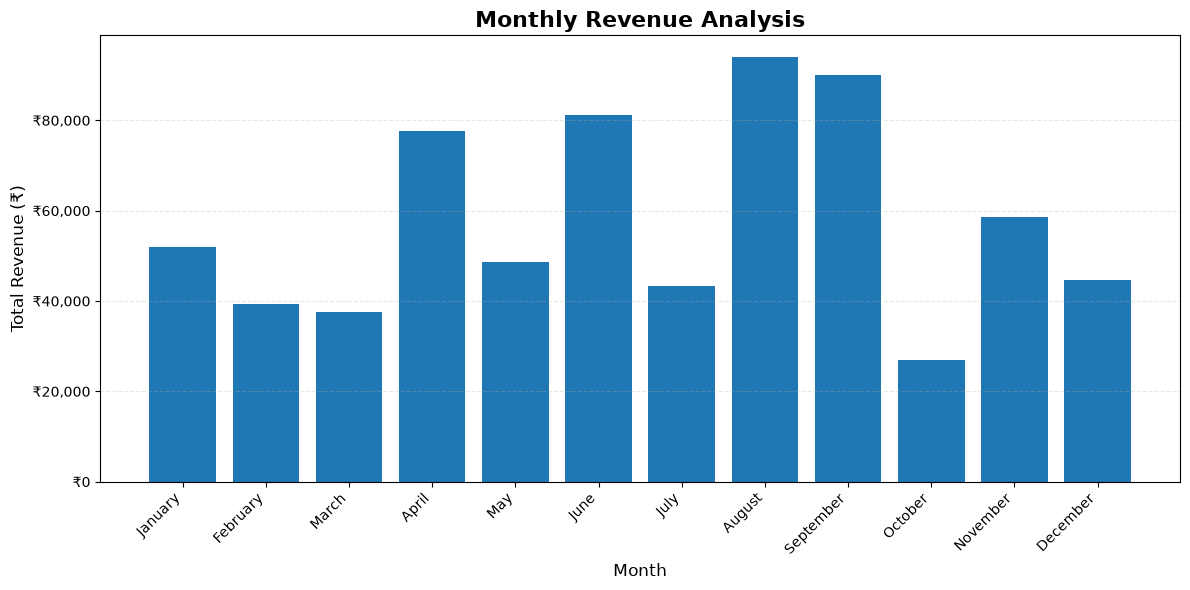

In [89]:


from matplotlib.ticker import FuncFormatter

months = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

plt.figure(figsize=(12, 6))

plt.bar(months, revenue_summary["Revenue"].reindex(range(1, 13)))

plt.title("Monthly Revenue Analysis", fontsize=16, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Revenue (₹)", fontsize=12)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:,.0f}")
)

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### Monthly Revenue Analysis

- August generated the highest monthly revenue of ₹94,121.76.
- October recorded the lowest monthly revenue of ₹26,986.55.
- Revenue fluctuated considerably throughout the year.
- The business should investigate October's performance by examining order count and average revenue per order.

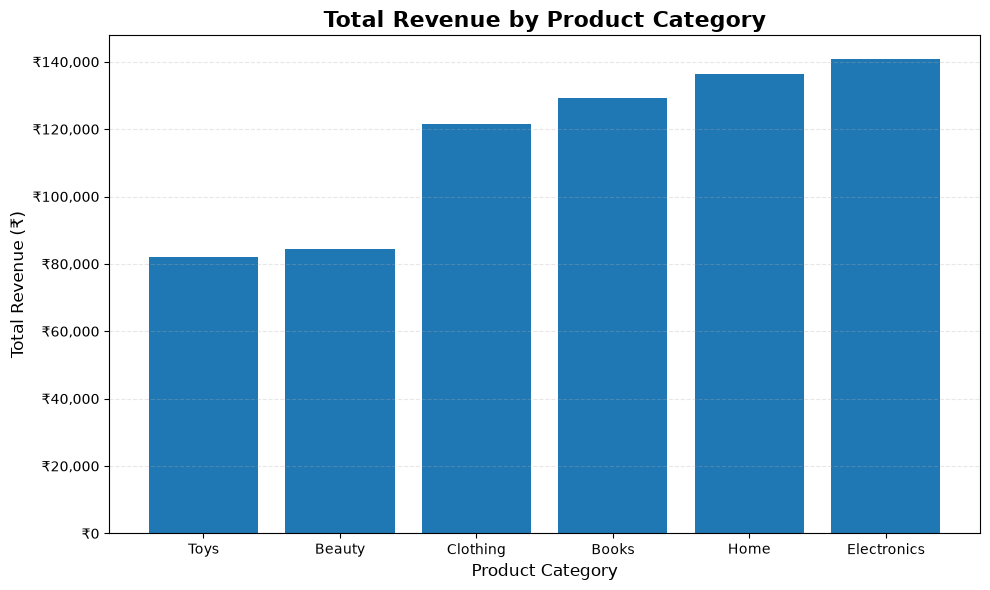

In [90]:

category_revenue = prod_cat_summary["Revenue"].sort_values()

plt.figure(figsize=(10, 6))

plt.bar(category_revenue.index, category_revenue.values)

plt.title("Total Revenue by Product Category",
          fontsize=16, fontweight="bold")
plt.xlabel("Product Category", fontsize=12)
plt.ylabel("Total Revenue (₹)", fontsize=12)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:,.0f}")
)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### Product Category Revenue Analysis

- Electronics generated the highest total revenue of ₹140,811.26.
- Toys generated the lowest total revenue among the product categories, at ₹81,902.93.
- Home generated ₹136,365.47, which was close to Electronics revenue.
- The business should investigate ways to improve Toys revenue and understand the factors contributing to strong Electronics and Home performance.

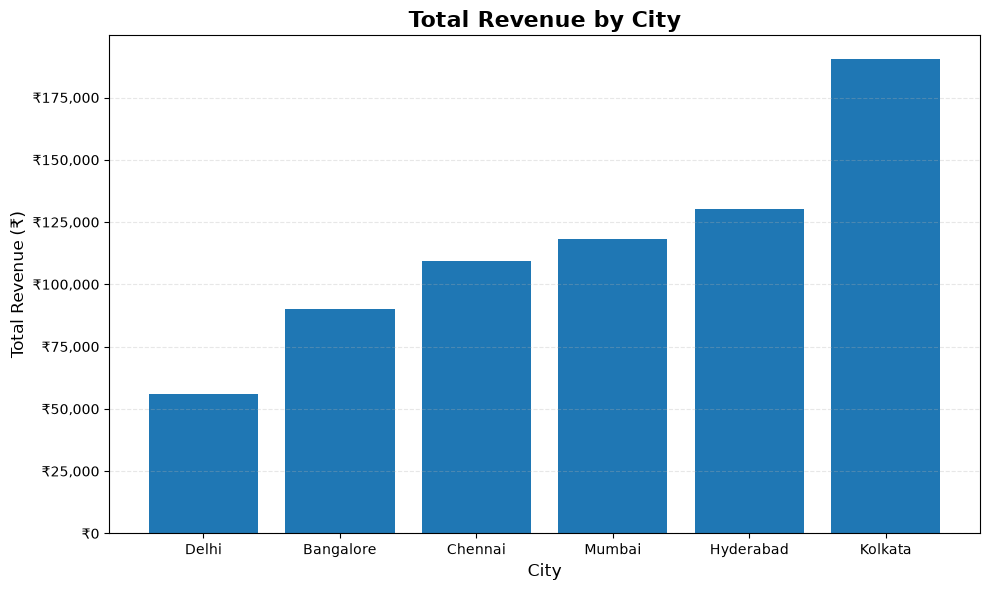

In [91]:

city_revenue = city_summary["Revenue"].sort_values()

plt.figure(figsize=(10, 6))

plt.bar(city_revenue.index, city_revenue.values)

plt.title("Total Revenue by City", fontsize=16, fontweight="bold")
plt.xlabel("City", fontsize=12)
plt.ylabel("Total Revenue (₹)", fontsize=12)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:,.0f}")
)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### City-wise Revenue Analysis

- Kolkata generated the highest total revenue of ₹190,462.98.
- Delhi generated the lowest total revenue of ₹55,782.47.
- Chennai had the highest order count, with 22 orders, but Kolkata generated higher total revenue with 20 orders.
- The business should compare order volume and revenue per order across cities to understand differences in performance.

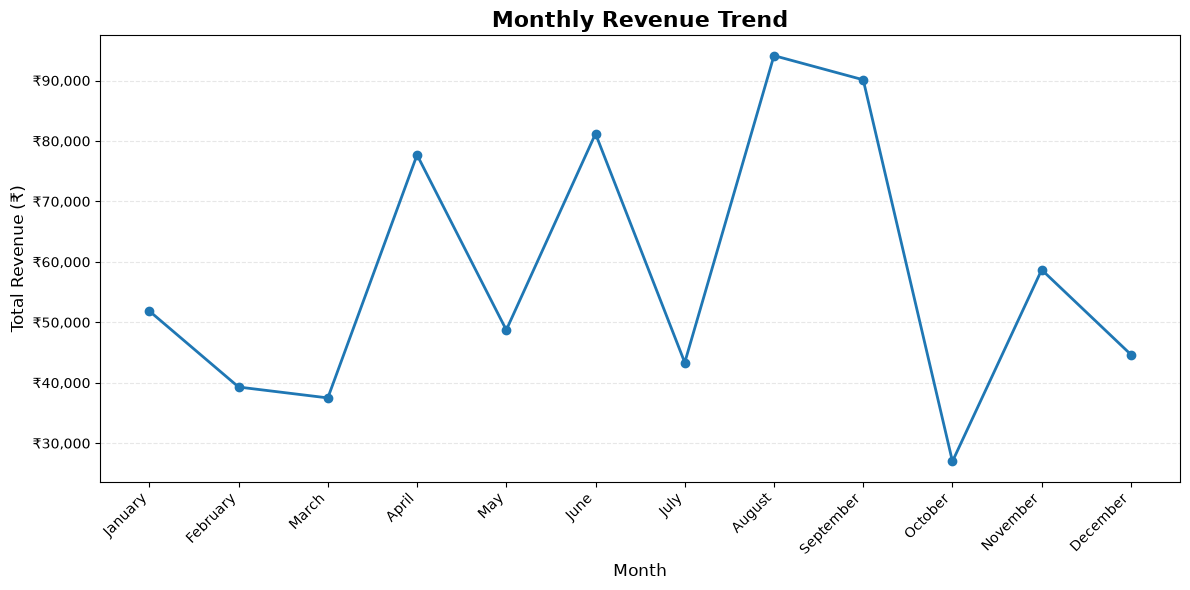

In [92]:

monthly_revenue = revenue_summary["Revenue"].reindex(range(1, 13))

plt.figure(figsize=(12, 6))

plt.plot(
    months,
    monthly_revenue.values,
    marker="o",
    linewidth=2,
    markersize=6
)

plt.title("Monthly Revenue Trend", fontsize=16, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Revenue (₹)", fontsize=12)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"₹{x:,.0f}")
)

plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


### Monthly Revenue Trend Analysis

- Revenue increased sharply from March to April and again from July to August.
- August recorded the highest monthly revenue of ₹94,121.76.
- Revenue declined slightly in September and dropped sharply in October, reaching ₹26,986.55.
- Revenue recovered in November before declining again in December.
- The business should investigate monthly order counts and average revenue per order to better understand these fluctuations.

## Key Business Insights

1. **Monthly Revenue:** August generated the highest revenue, while October recorded the lowest revenue. The business should investigate the reasons behind October's decline by examining order count, average revenue per order, and product category performance.

2. **Product Category:** Electronics generated the highest total revenue among all product categories. The business can study its successful products and pricing strategies to identify opportunities for other categories.

3. **City Performance:** Kolkata generated the highest total revenue among the analyzed cities. The business can investigate factors such as order volume and average revenue per order to understand its performance.

## Recommendations

1. **Improve Low-Revenue Months:** Investigate October's low revenue by comparing order count, average revenue per order, and product category performance.
2. **Strengthen Product Categories:** Study the performance of Electronics, the highest-revenue category, and identify opportunities to improve revenue in lower-performing categories such as Toys.
3. **Analyze City Performance:** Examine Kolkata's sales performance and compare it with other cities to identify potential growth opportunities.

*Note: These recommendations are based on patterns observed in the available dataset. Further analysis is required to confirm the underlying causes.*